In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [ ]:
# ---------------------------------------------------------
# 1. DATA ACCESSING & INITIAL AUDIT (Rubric Category 1)
# ---------------------------------------------------------

df = pd.read_csv('water_potability.csv')
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [15]:
print("Dataset Shape:", df.shape)
print("\nMissing Values per Column:\n", df.isnull().sum())
print("\nSummary Statistics:\n", df.describe().T[['mean', 'std', 'min', 'max']])

Dataset Shape: (3276, 12)

Missing Values per Column:
 ph                        491
Hardness                    0
Solids                      0
Chloramines                 0
Sulfate                   781
Conductivity                0
Organic_carbon              0
Trihalomethanes           162
Turbidity                   0
Potability                  0
TDS_Conductivity_Ratio      0
Sulfate_Missing_Flag        0
dtype: int64

Summary Statistics:
                                 mean          std         min           max
ph                          7.080795     1.594320    0.000000     14.000000
Hardness                  196.369496    32.879761   47.432000    323.124000
Solids                  22014.092526  8768.570828  320.942611  61227.196008
Chloramines                 7.122277     1.583085    0.352000     13.127000
Sulfate                   333.775777    41.416840  129.000000    481.030642
Conductivity              426.205111    80.824064  181.483754    753.342620
Organic_carbon    

In [12]:
# ---------------------------------------------------------
# 2. DATA CLEANSING & FEATURE ENGINEERING (Rubric Category 1)
# ---------------------------------------------------------
# Check for duplicate records
df = df.drop_duplicates()

# Domain-informed feature engineering (Chemistry context):
# Ratio of Solids (TDS) to Conductivity gives insight into ionic composition
df['TDS_Conductivity_Ratio'] = df['Solids'] / (df['Conductivity'] + 1e-5)

# Indicator flag for missing sulfate readings (often non-random in lab testing)
df['Sulfate_Missing_Flag'] = df['Sulfate'].isnull().astype(int)

# Separate features and target before imputation to prevent data leakage
X = df.drop('Potability', axis=1)
y = df['Potability']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [13]:
# ---------------------------------------------------------
# 4. PREDICTIVE MODELING PIPELINE (Rubric Category 4)
# ---------------------------------------------------------
# Build a leakage-free pipeline: KNN Imputation -> Scaling -> Random Forest
rf_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight='balanced'))
])

# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"\n5-Fold CV ROC-AUC: {cv_auc.mean():.3f} (+/- {cv_auc.std():.3f})")

# Fit on full training set and evaluate on hold-out test set
rf_pipeline.fit(X_train, y_train)
y_pred = rf_pipeline.predict(X_test)
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

print("\nTest Set ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


5-Fold CV ROC-AUC: 0.679 (+/- 0.017)

Test Set ROC-AUC: 0.679

Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.79      0.74       400
           1       0.58      0.46      0.52       256

    accuracy                           0.66       656
   macro avg       0.64      0.63      0.63       656
weighted avg       0.65      0.66      0.65       656



In [14]:
# ---------------------------------------------------------
# 3. STATISTICAL HYPOTHESIS TESTING (Rubric Category 4)
# ---------------------------------------------------------
# Mann-Whitney U test: Does pH significantly differ between potable and non-potable water?
potable_ph = df[df['Potability'] == 1]['ph'].dropna()
non_potable_ph = df[df['Potability'] == 0]['ph'].dropna()

u_stat, p_val = stats.mannwhitneyu(potable_ph, non_potable_ph)
print(f"\nMann-Whitney U Test for pH vs Potability: U={u_stat:.2f}, p-value={p_val:.4f}")


Mann-Whitney U Test for pH vs Potability: U=924654.00, p-value=0.9084


Dataset Shape: (3276, 10)

Missing Values per Column:
 ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Summary Statistics:
                          mean          std         min           max
ph                   7.080795     1.594320    0.000000     14.000000
Hardness           196.369496    32.879761   47.432000    323.124000
Solids           22014.092526  8768.570828  320.942611  61227.196008
Chloramines          7.122277     1.583085    0.352000     13.127000
Sulfate            333.775777    41.416840  129.000000    481.030642
Conductivity       426.205111    80.824064  181.483754    753.342620
Organic_carbon      14.284970     3.308162    2.200000     28.300000
Trihalomethanes     66.396293    16.175008    0.738000    124.000000
Turbidity            3.966786     0.780382    1.450000     

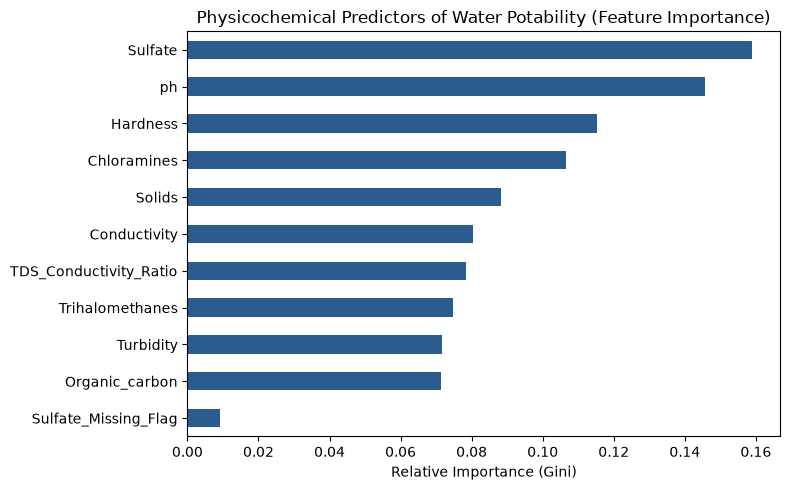

In [ ]:
# ---------------------------------------------------------
# 5. VISUALIZATION FOR REPORTING (Rubric Category 3)
# ---------------------------------------------------------
# Plot Feature Importance
importances = rf_pipeline.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
feat_imp.plot(kind='barh', color='#2b5c8f')
plt.title('Physicochemical Predictors of Water Potability (Feature Importance)')
plt.xlabel('Relative Importance (Gini)')
plt.tight_layout()
plt.savefig('water_feature_importance.png', dpi=300)
plt.show()